## Практическая работа №2

### Выполнил: Зацепин Максим Андреевич, студент группы М092602(77)

In [465]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv("day.csv")

df["dteday"] = pd.to_datetime(df["dteday"])
df["Year"] = df["dteday"].dt.year
df["Month"] = df["dteday"].dt.month
df["Day"] = df["dteday"].dt.day

df["User_Diff"] = df["registered"] - df["casual"]
df["User_Ratio"] = df["registered"] / df["cnt"]

season_names = {
    1: "Весна",
    2: "Лето",
    3: "Осень",
    4: "Зима"
}
df["Season_Name"] = df["season"].map(season_names)
df["Year_Label"] = df["Year"].astype(str)

sns.set_theme()
df

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,casual,registered,cnt,Year,Month,Day,User_Diff,User_Ratio,Season_Name,Year_Label
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,331,654,985,2011,1,1,323,0.663959,Весна,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,131,670,801,2011,1,2,539,0.836454,Весна,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,120,1229,1349,2011,1,3,1109,0.911045,Весна,2011
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,...,108,1454,1562,2011,1,4,1346,0.930858,Весна,2011
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,...,82,1518,1600,2011,1,5,1436,0.948750,Весна,2011
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
726,727,2012-12-27,1,1,12,0,4,1,2,0.254167,...,247,1867,2114,2012,12,27,1620,0.883160,Весна,2012
727,728,2012-12-28,1,1,12,0,5,1,2,0.253333,...,644,2451,3095,2012,12,28,1807,0.791922,Весна,2012
728,729,2012-12-29,1,1,12,0,6,0,2,0.253333,...,159,1182,1341,2012,12,29,1023,0.881432,Весна,2012
729,730,2012-12-30,1,1,12,0,0,0,1,0.255833,...,364,1432,1796,2012,12,30,1068,0.797327,Весна,2012


## Часть 1. Стили и контексты

### 1.1. Функция для отрисовки синусоид

In [466]:
def sinplot(flip=1):
    x = np.linspace(0, 14, 100)
    for i in range(1, 7):
        plt.plot(x, np.sin(x + i * .5) * (7 - i) * flip)


### 1.2. Сетка графиков в четырёх контекстах

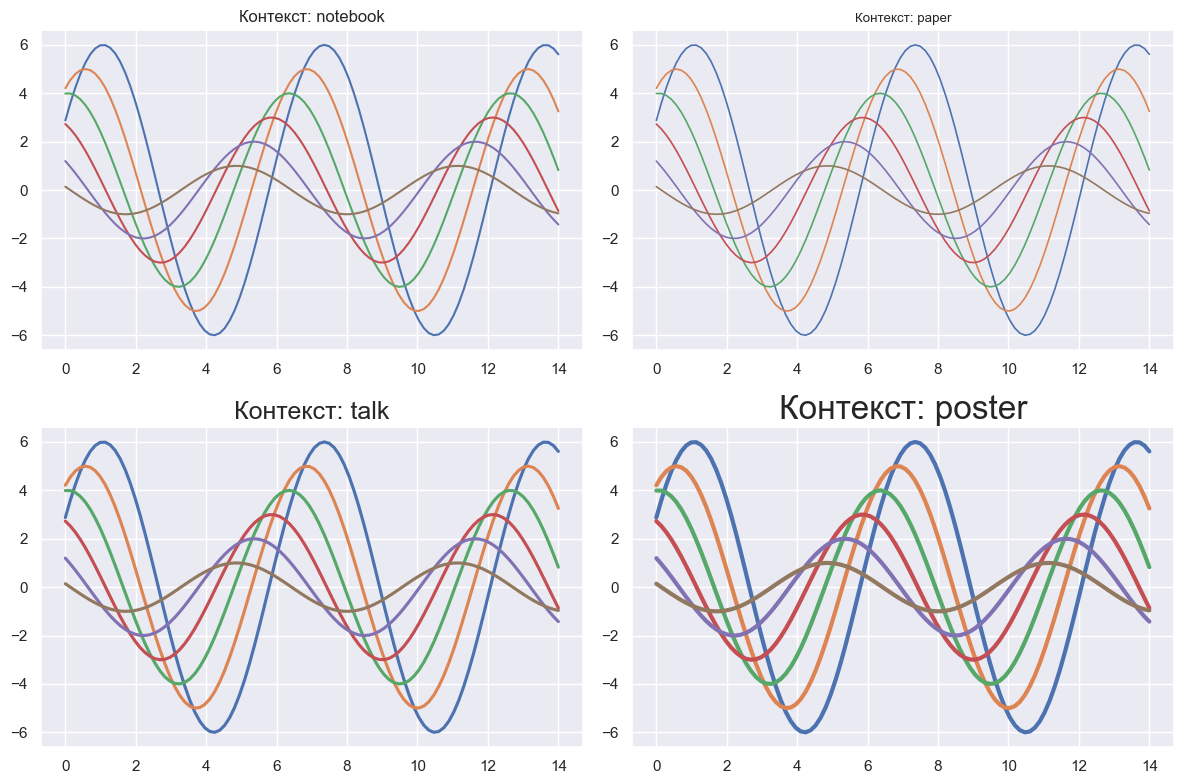

In [467]:
contexts = ["notebook", "paper", "talk", "poster"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, context in zip(axes.flat, contexts):
    with sns.plotting_context(context):
        plt.sca(ax)
        sinplot()
        ax.set_title("Контекст: " + context)

plt.tight_layout()
plt.show()

### 1.3. Стили осей

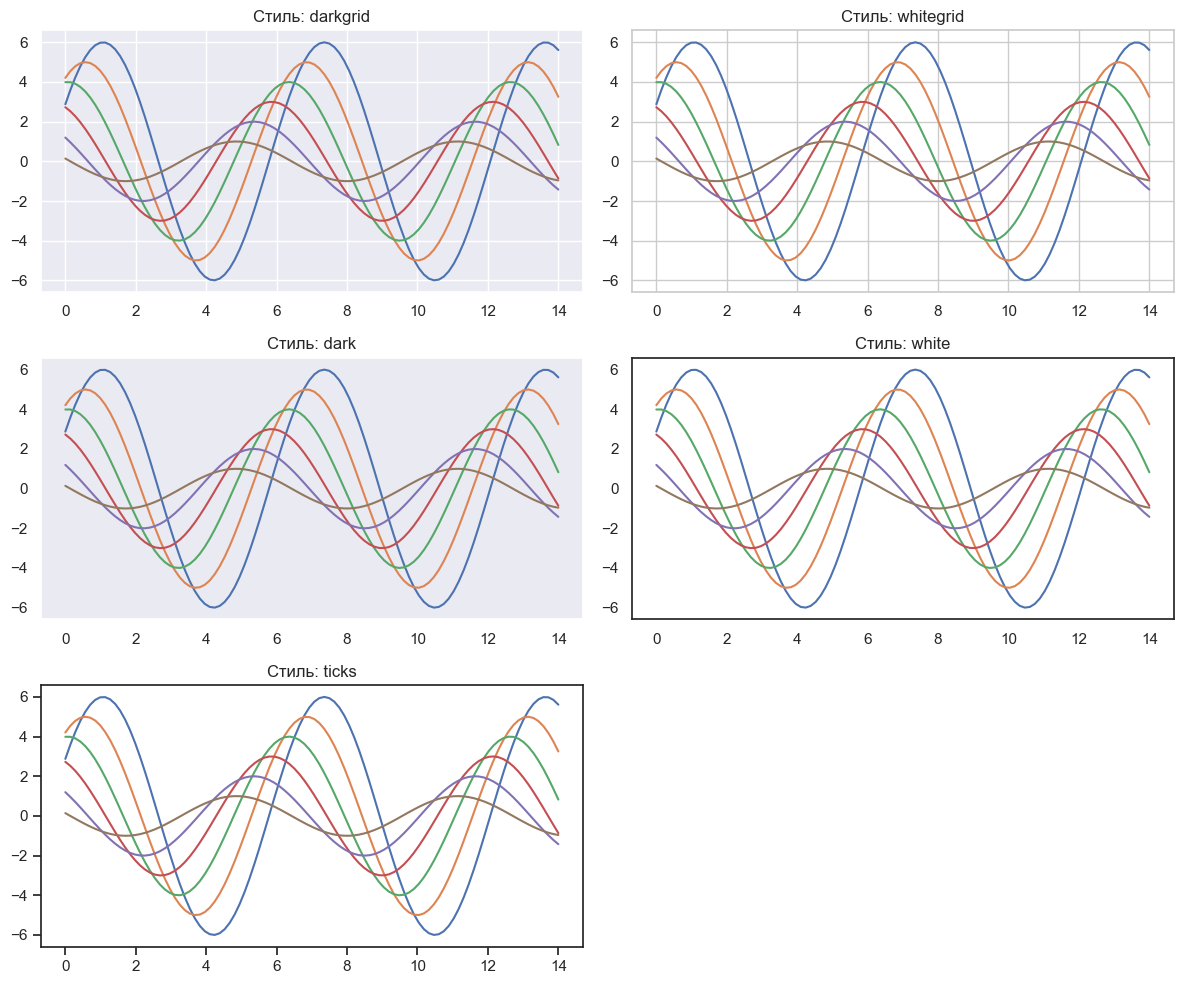

In [468]:
styles = ["darkgrid", "whitegrid", "dark", "white", "ticks"]

fig, axes = plt.subplots(3, 2, figsize=(12, 10))

for ax, style in zip(axes.flat, styles):
    ax.remove()

    with sns.axes_style(style):
        ax = fig.add_subplot(3, 2, list(axes.flat).index(ax) + 1)
        sinplot()
        ax.set_title("Стиль: " + style)

axes.flat[-1].axis("off")

plt.tight_layout()
plt.show()

### 1.4. Использование sns.despine()

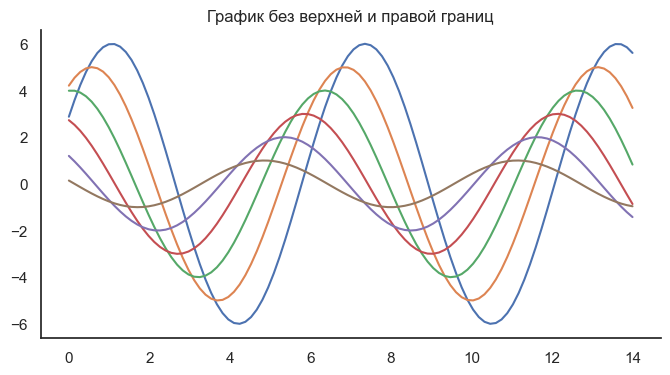

In [469]:

with sns.axes_style("white"):
    plt.figure(figsize=(8, 4))
    sinplot()

    # Убираем верхнюю и правую границы рамки.
    # Левая и нижняя обычно остаются, чтобы было проще считывать значения по осям.
    sns.despine()

    plt.title("График без верхней и правой границ")
    plt.show()


### 1.5. Контекстные менеджеры

Контекстные менеджеры позволяют применять оформление только к нужному участку кода. Это полезно, если в одном блокноте требуется построить несколько графиков с разными стилями, не изменяя глобальные настройки.

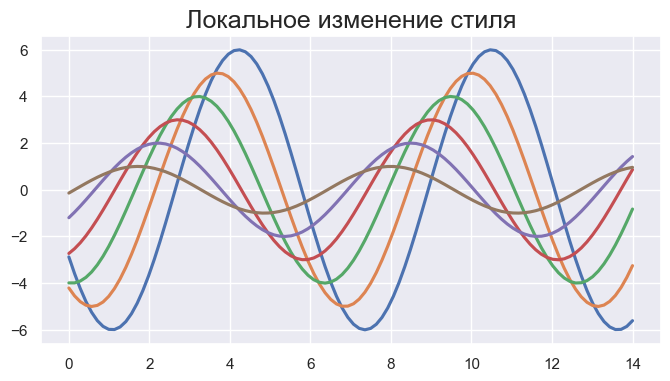

In [470]:
fig, ax = plt.subplots(figsize=(8, 4))

with sns.axes_style("darkgrid"), sns.plotting_context("talk"):
    plt.sca(ax)
    sinplot(flip=-1)
    ax.set_title("Локальное изменение стиля")

plt.show()

## Часть 2. Палитры

### 2.1. Последовательная, расходящаяся и категориальная палитры

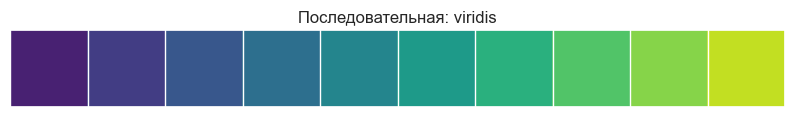

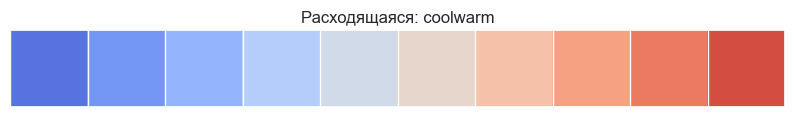

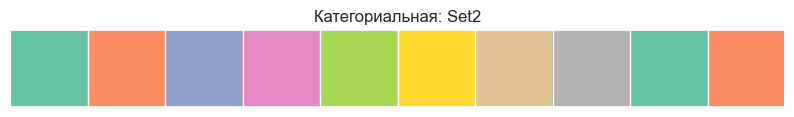

In [471]:
palettes = {
    "Последовательная: viridis": sns.color_palette("viridis", 10),
    "Расходящаяся: coolwarm": sns.color_palette("coolwarm", 10),
    "Категориальная: Set2": sns.color_palette("Set2", 10)
}

for name, palette in palettes.items():
    sns.palplot(palette)
    plt.title(name)
    plt.show()


### 2.2. Палитра jet

В современных версиях Seaborn палитра jet может не поддерживаться напрямую, для демонстрации используем её из Matplotlib.

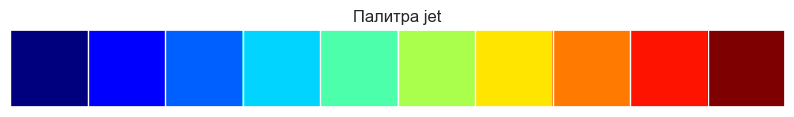

In [472]:

jet_colors = [plt.cm.jet(x) for x in np.linspace(0, 1, 10)]

sns.palplot(jet_colors)
plt.title("Палитра jet")
plt.show()


Палитра jet имеет неравномерные изменения яркости. Из-за этого на графике могут появляться ложные визуальные границы, которые не соответствуют реальным различиям в данных. Для статистической визуализации это критично, т.к цвет не должен создавать впечатление резкого изменения там, где его нет

### 2.3. Собственная палитра

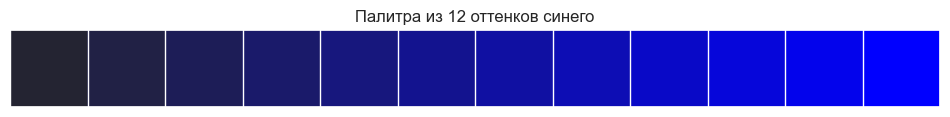

In [473]:
blue_colors = sns.dark_palette("blue", n_colors=12)

sns.palplot(blue_colors)
plt.title("Палитра из 12 оттенков синего")
plt.show()


### 2.4. Сравнение палитр

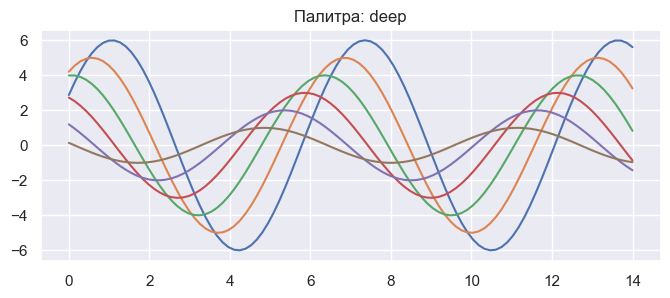

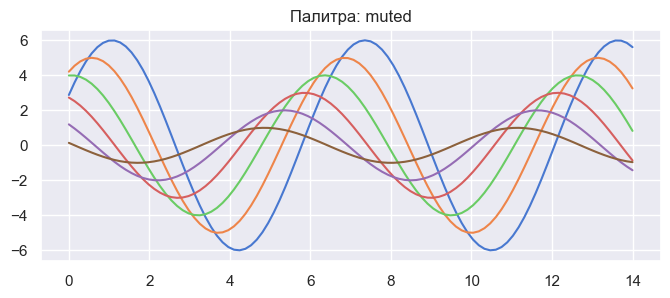

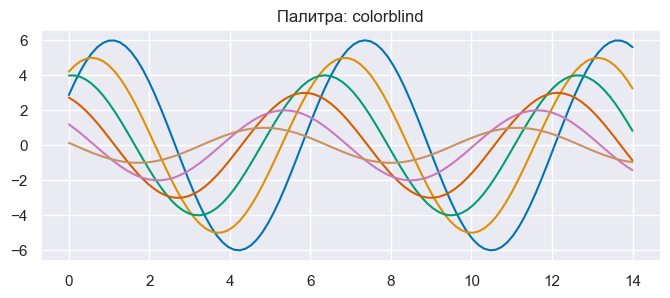

In [474]:
for palette_name in ["deep", "muted", "colorblind"]:
    with sns.color_palette(palette_name):
        plt.figure(figsize=(8, 3))
        sinplot()
        plt.title("Палитра: " + palette_name)
        plt.show()


- deep подходит для стандартных графиков
- muted - для спокойного оформления
- colorblind — когда важно, чтобы цвета оставались различимыми для людей с нарушениями цветового зрения

## Часть 3. Сравнение Matplotlib и Seaborn

### 3.1. Разведочный анализ

In [475]:
print("Размер датасета:", df.shape)

display(df.head())

Размер датасета: (731, 23)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,...,casual,registered,cnt,Year,Month,Day,User_Diff,User_Ratio,Season_Name,Year_Label
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,...,331,654,985,2011,1,1,323,0.663959,Весна,2011
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,...,131,670,801,2011,1,2,539,0.836454,Весна,2011
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,...,120,1229,1349,2011,1,3,1109,0.911045,Весна,2011
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,...,108,1454,1562,2011,1,4,1346,0.930858,Весна,2011
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,...,82,1518,1600,2011,1,5,1436,0.948750,Весна,2011


In [476]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 23 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   instant      731 non-null    int64         
 1   dteday       731 non-null    datetime64[ns]
 2   season       731 non-null    int64         
 3   yr           731 non-null    int64         
 4   mnth         731 non-null    int64         
 5   holiday      731 non-null    int64         
 6   weekday      731 non-null    int64         
 7   workingday   731 non-null    int64         
 8   weathersit   731 non-null    int64         
 9   temp         731 non-null    float64       
 10  atemp        731 non-null    float64       
 11  hum          731 non-null    float64       
 12  windspeed    731 non-null    float64       
 13  casual       731 non-null    int64         
 14  registered   731 non-null    int64         
 15  cnt          731 non-null    int64         
 16  Year    

In [477]:
display(df.describe().T)

,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


In [478]:
numeric_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Числовые признаки:", numeric_columns)
print("Категориальные признаки:", categorical_columns)

print("\nСреднее число поездок по годам:")
display(df.groupby("Year")["cnt"].mean().round(2))

Числовые признаки: ['instant', 'season', 'yr', 'mnth', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt', 'Year', 'Month', 'Day', 'User_Diff', 'User_Ratio']
Категориальные признаки: ['Season_Name', 'Year_Label']

Среднее число поездок по годам:


Year
2011    3405.76
2012    5599.93
Name: cnt, dtype: float64

### 3.2. Построение графиков

#### А. Линейный график: поездки по типам пользователей

Matplotlib:

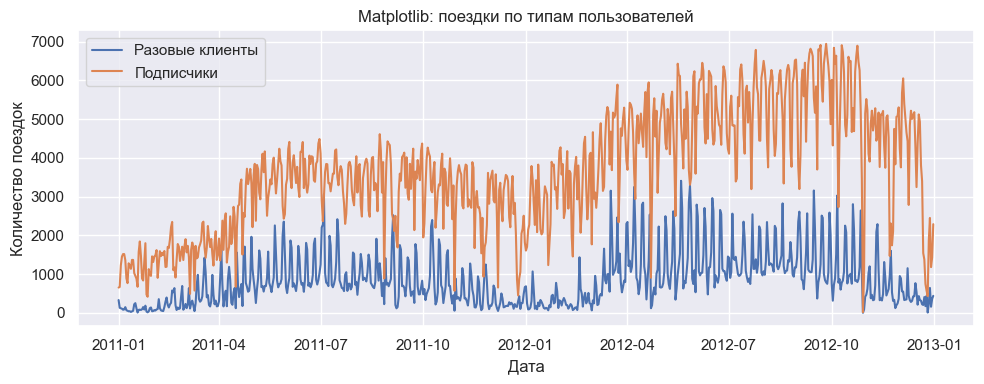

In [479]:
plt.figure(figsize=(10, 4))

plt.plot(df["dteday"], df["casual"], label="Разовые клиенты")
plt.plot(df["dteday"], df["registered"], label="Подписчики")

plt.title("Matplotlib: поездки по типам пользователей")
plt.xlabel("Дата")
plt.ylabel("Количество поездок")
plt.legend()
plt.tight_layout()
plt.show()

Seaborn:

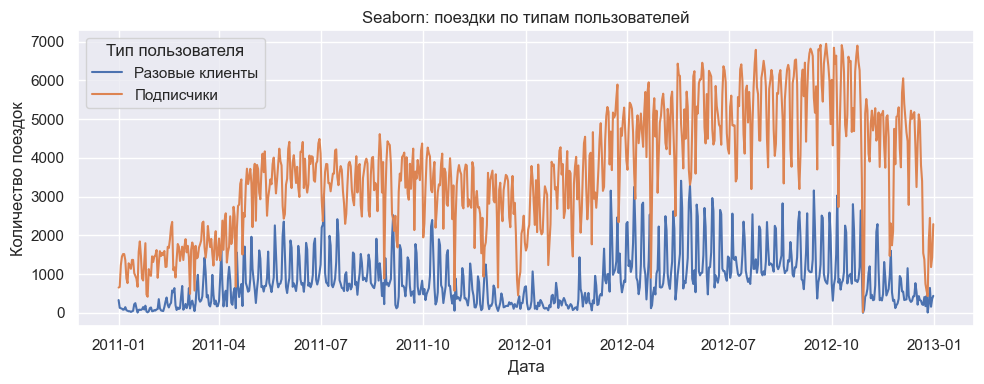

In [480]:
users_long = df.melt(
    id_vars="dteday",
    value_vars=["casual", "registered"],
    var_name="Тип пользователя",
    value_name="Поездки"
)

users_long["Тип пользователя"] = users_long["Тип пользователя"].map({
    "casual": "Разовые клиенты",
    "registered": "Подписчики"
})

plt.figure(figsize=(10, 4))
sns.lineplot(
    data=users_long,
    x="dteday",
    y="Поездки",
    hue="Тип пользователя"
)

plt.title("Seaborn: поездки по типам пользователей")
plt.xlabel("Дата")
plt.ylabel("Количество поездок")
plt.tight_layout()
plt.show()


#### Б. Гистограмма: распределение дневного спроса по годам

Matplotlib:

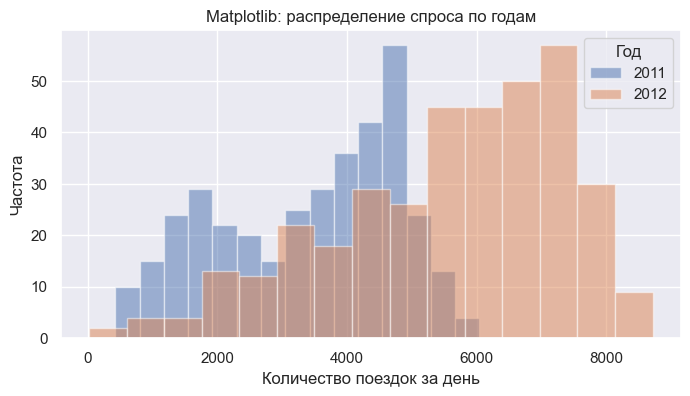

In [481]:

plt.figure(figsize=(8, 4))

for year, part in df.groupby("Year"):
    plt.hist(part["cnt"], bins=15, alpha=0.5, label=str(year))

plt.title("Matplotlib: распределение спроса по годам")
plt.xlabel("Количество поездок за день")
plt.ylabel("Частота")
plt.legend(title="Год")
plt.show()


Seaborn:

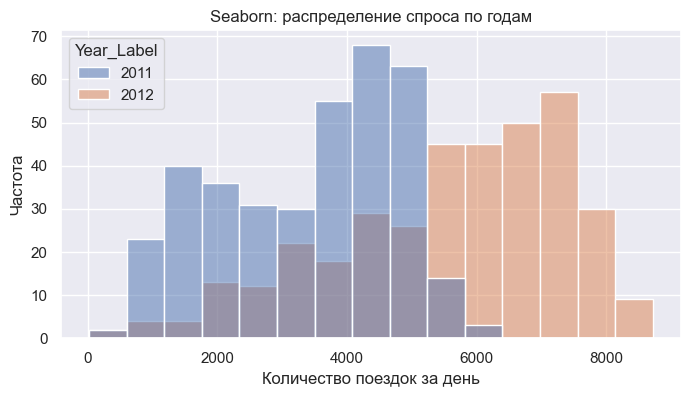

In [482]:

plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="cnt",
    hue="Year_Label",
    bins=15,
    alpha=0.5
)

plt.title("Seaborn: распределение спроса по годам")
plt.xlabel("Количество поездок за день")
plt.ylabel("Частота")
plt.show()


#### В. KDE: плотность распределения дневного спроса

Matplotlib:

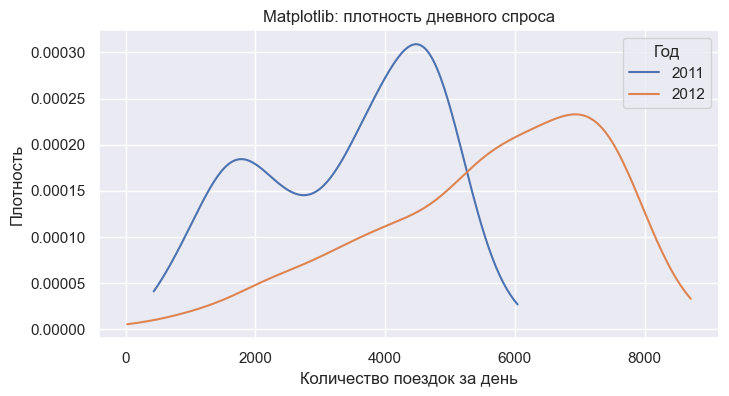

In [483]:
plt.figure(figsize=(8, 4))

for year, part in df.groupby("Year"):
    values = part["cnt"].dropna()
    density = stats.gaussian_kde(values)
    x_grid = np.linspace(values.min(), values.max(), 200)

    plt.plot(x_grid, density(x_grid), label=str(year))

plt.title("Matplotlib: плотность дневного спроса")
plt.xlabel("Количество поездок за день")
plt.ylabel("Плотность")
plt.legend(title="Год")
plt.show()

Seaborn:

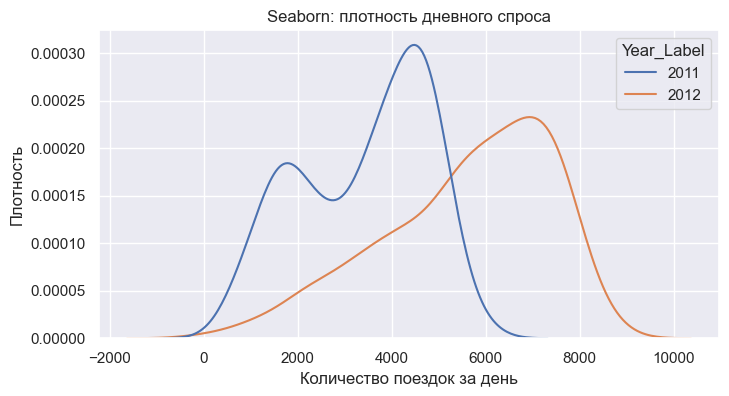

In [484]:
plt.figure(figsize=(8, 4))

sns.kdeplot(
    data=df,
    x="cnt",
    hue="Year_Label",
    common_norm=False
)

plt.title("Seaborn: плотность дневного спроса")
plt.xlabel("Количество поездок за день")
plt.ylabel("Плотность")
plt.show()


#### Г. Boxplot: спрос по сезонам

Matplotlib:

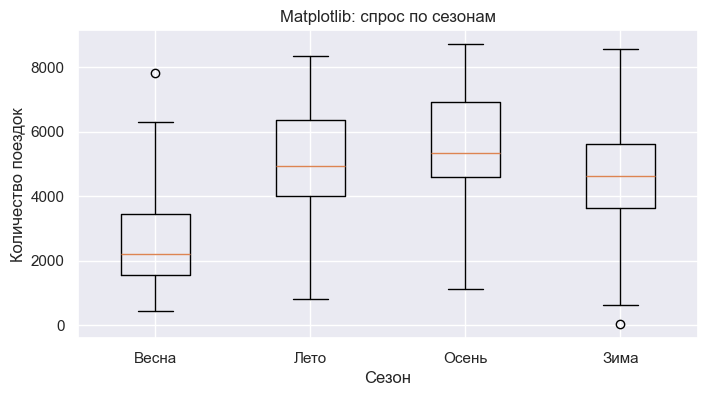

In [485]:
season_order = ["Весна", "Лето", "Осень", "Зима"]

season_values = [
    df.loc[df["Season_Name"] == season, "cnt"].dropna().values
    for season in season_order
]

plt.figure(figsize=(8, 4))
plt.boxplot(season_values, tick_labels=season_order)

plt.title("Matplotlib: спрос по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Количество поездок")
plt.show()


Seaborn:

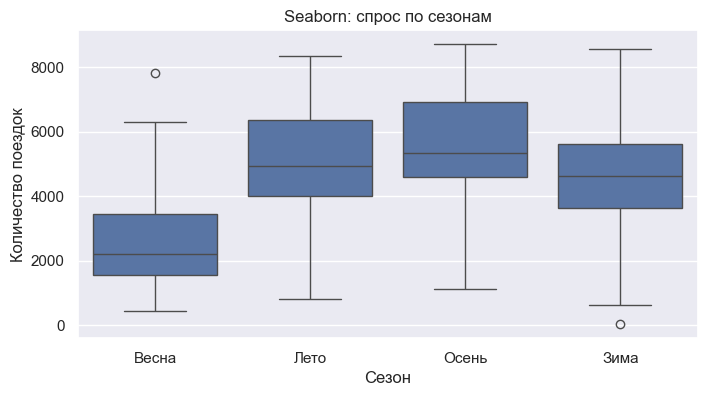

In [486]:

plt.figure(figsize=(8, 4))

sns.boxplot(
    data=df,
    x="Season_Name",
    y="cnt",
    order=season_order
)

plt.title("Seaborn: спрос по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Количество поездок")
plt.show()


#### Д. Violin plot: распределение спроса по сезонам

Matplotlib:

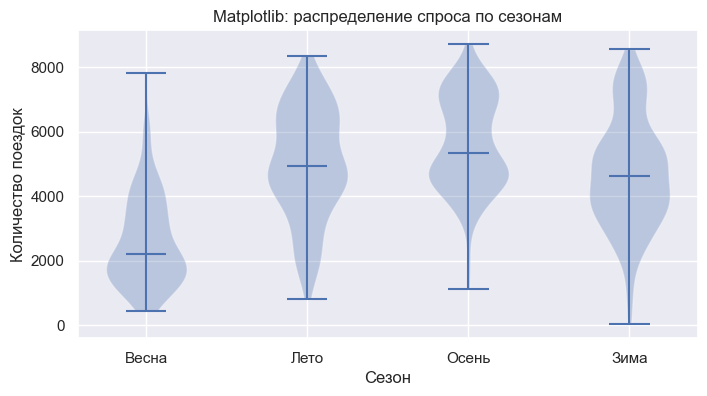

In [487]:
plt.figure(figsize=(8, 4))

plt.violinplot(season_values, showmedians=True)
plt.xticks(range(1, 5), season_order)

plt.title("Matplotlib: распределение спроса по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Количество поездок")
plt.show()


Seaborn:

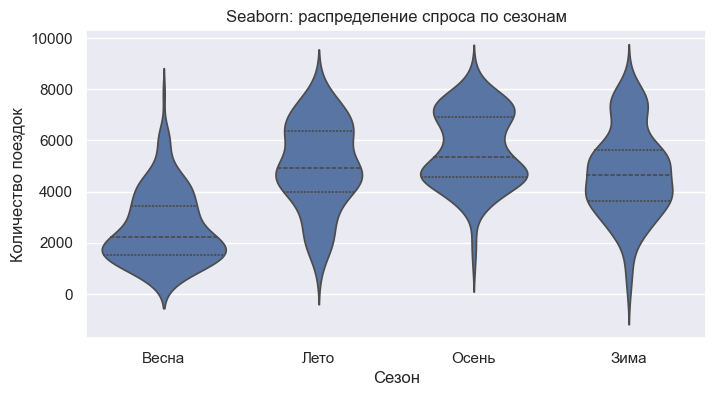

In [488]:
plt.figure(figsize=(8, 4))

sns.violinplot(
    data=df,
    x="Season_Name",
    y="cnt",
    order=season_order,
    inner="quartile"
)

plt.title("Seaborn: распределение спроса по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Количество поездок")
plt.show()

#### Е. Столбчатая диаграмма средних значений

Matplotlib:

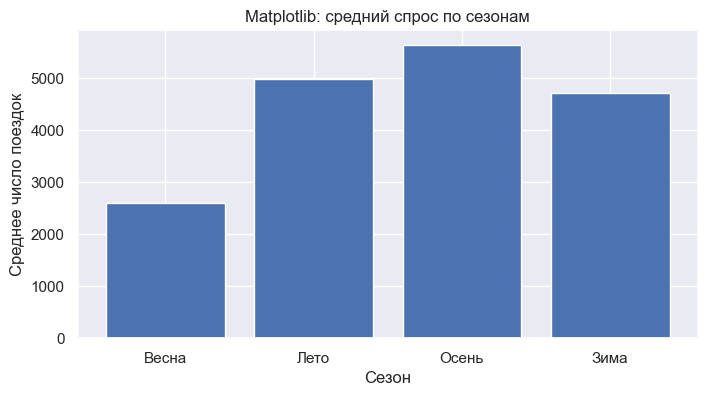

In [489]:
season_means = (
    df.groupby("Season_Name", observed=False)["cnt"]
    .mean()
    .reindex(season_order)
)

plt.figure(figsize=(8, 4))
plt.bar(season_means.index, season_means.values)

plt.title("Matplotlib: средний спрос по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Среднее число поездок")
plt.show()

Seaborn:

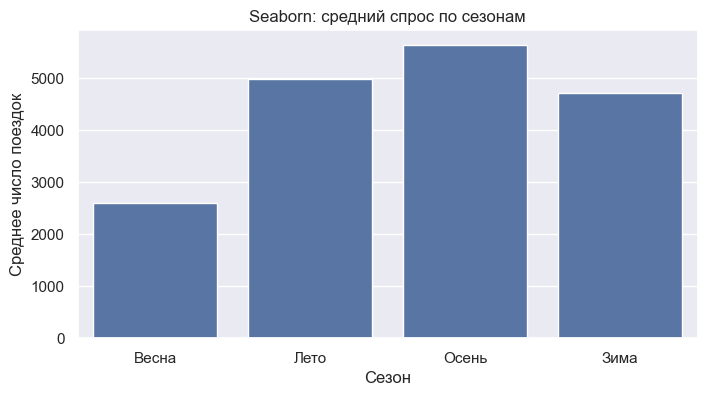

In [490]:
plt.figure(figsize=(8, 4))

sns.barplot(
    data=df,
    x="Season_Name",
    y="cnt",
    order=season_order,
    errorbar=None
)

plt.title("Seaborn: средний спрос по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Среднее число поездок")
plt.show()

#### Ж. Scatter plot: температура и спрос

Цвет показывает влажность, размер точек — скорость ветра.

Matplotlib:

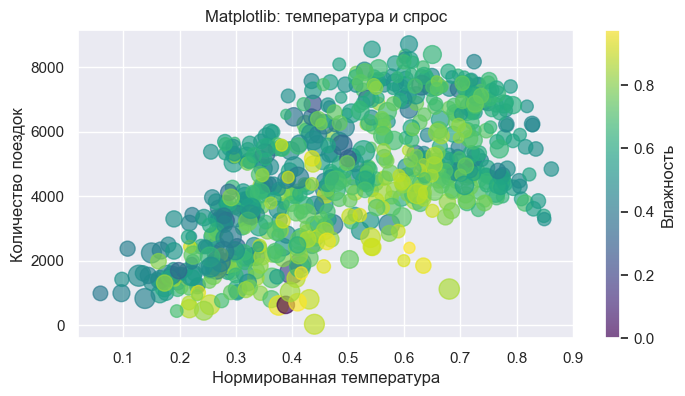

In [491]:
plt.figure(figsize=(8, 4))

points = plt.scatter(
    df["temp"],
    df["cnt"],
    c=df["hum"],
    s=25 + df["windspeed"] * 500,
    alpha=0.65,
    cmap="viridis"
)

plt.colorbar(points, label="Влажность")
plt.title("Matplotlib: температура и спрос")
plt.xlabel("Нормированная температура")
plt.ylabel("Количество поездок")
plt.show()

Seaborn:

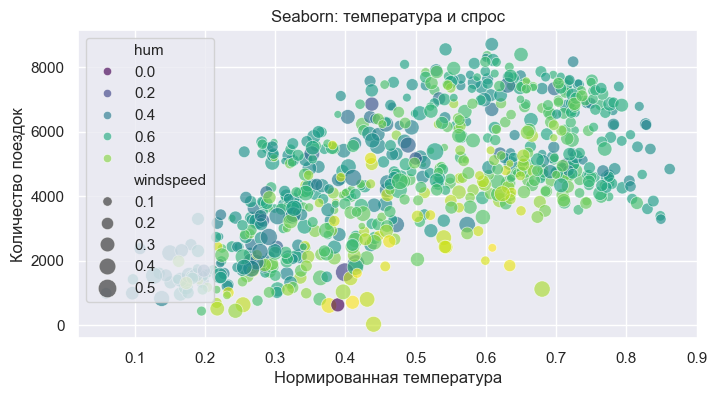

In [492]:
plt.figure(figsize=(8, 4))

sns.scatterplot(
    data=df,
    x="temp",
    y="cnt",
    hue="hum",
    size="windspeed",
    sizes=(20, 180),
    alpha=0.65,
    palette="viridis"
)

plt.title("Seaborn: температура и спрос")
plt.xlabel("Нормированная температура")
plt.ylabel("Количество поездок")
plt.show()

#### З. Гистограмма и KDE

Matplotlib:

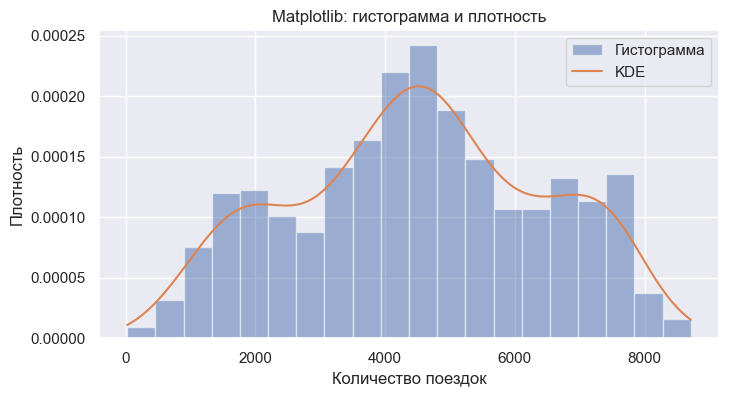

In [493]:
plt.figure(figsize=(8, 4))

plt.hist(df["cnt"], bins=20, density=True, alpha=0.5, label="Гистограмма")

density = stats.gaussian_kde(df["cnt"].dropna())
x_grid = np.linspace(df["cnt"].min(), df["cnt"].max(), 250)

plt.plot(x_grid, density(x_grid), label="KDE")

plt.title("Matplotlib: гистограмма и плотность")
plt.xlabel("Количество поездок")
plt.ylabel("Плотность")
plt.legend()
plt.show()

Seaborn:

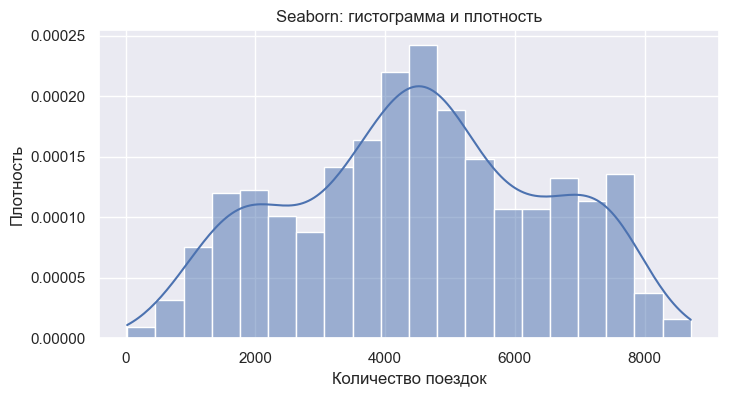

In [494]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df,
    x="cnt",
    bins=20,
    stat="density",
    kde=True
)

plt.title("Seaborn: гистограмма и плотность")
plt.xlabel("Количество поездок")
plt.ylabel("Плотность")
plt.show()

#### И. Pairplot: попарные зависимости признаков

Matplotlib:

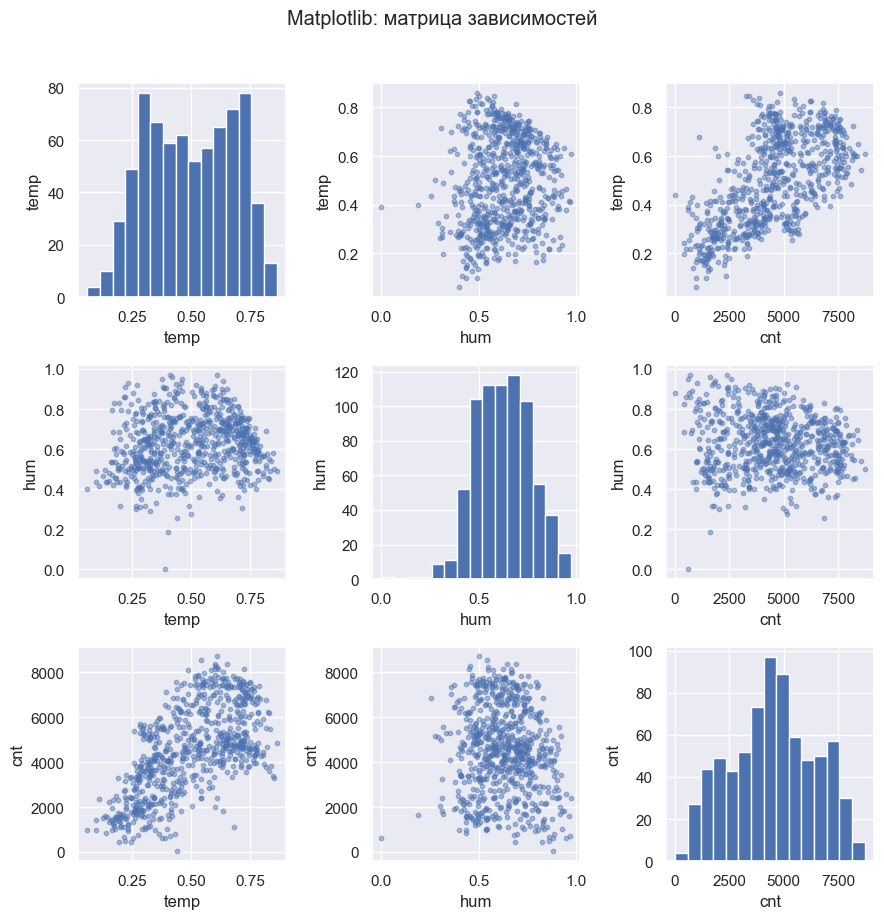

In [495]:
pair_features = ["temp", "hum", "cnt"]

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for i, y_name in enumerate(pair_features):
    for j, x_name in enumerate(pair_features):
        ax = axes[i, j]

        if i == j:
            ax.hist(df[x_name].dropna(), bins=15)
        else:
            ax.scatter(df[x_name], df[y_name], s=10, alpha=0.45)

        ax.set_xlabel(x_name)
        ax.set_ylabel(y_name)

fig.suptitle("Matplotlib: матрица зависимостей", y=1.02)
plt.tight_layout()
plt.show()

Seaborn:

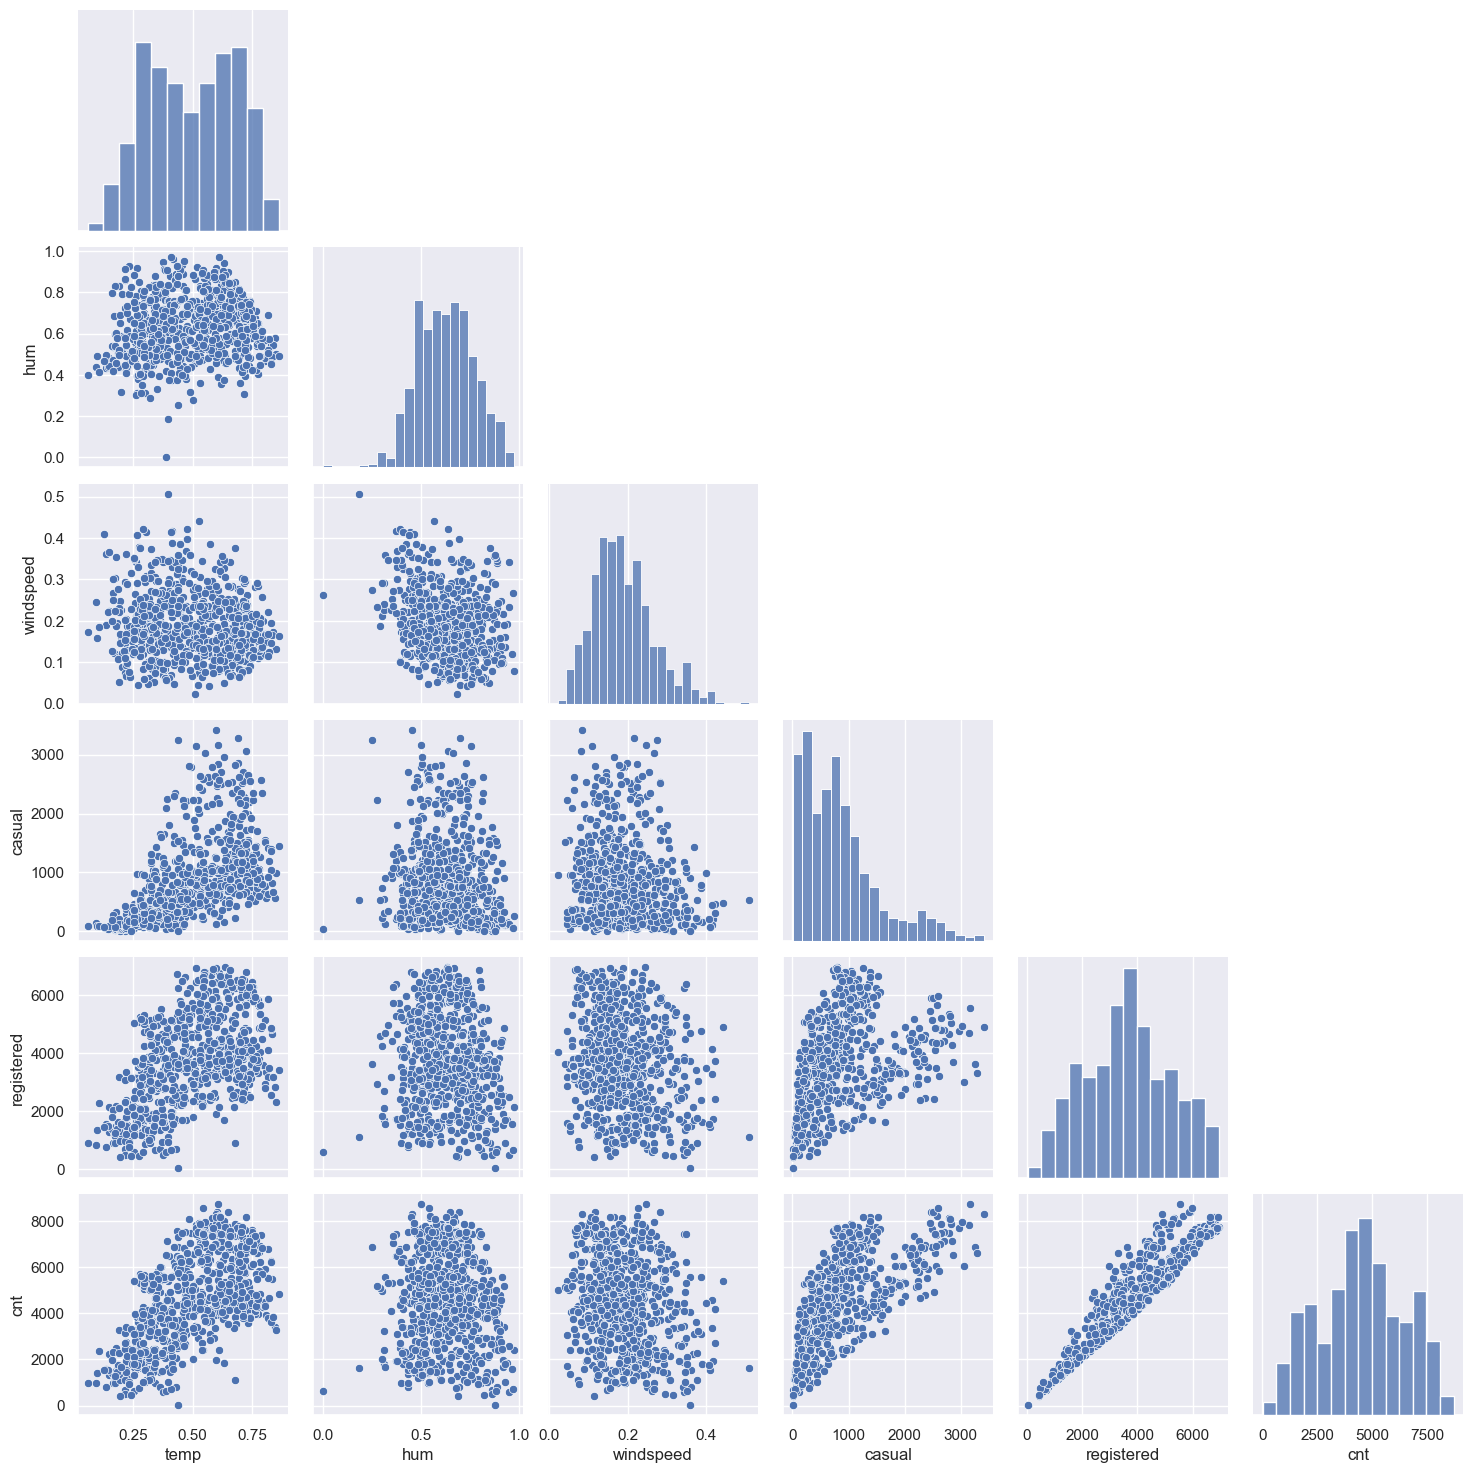

In [496]:
sns.pairplot(
    df[["temp", "hum", "windspeed", "casual", "registered", "cnt"]],
    corner=True,
    diag_kind="hist"
)

plt.show()

#### К. Тепловая карта корреляций

Используются все числовые признаки датасета, а не только несколько выбранных показателей.

Matplotlib:

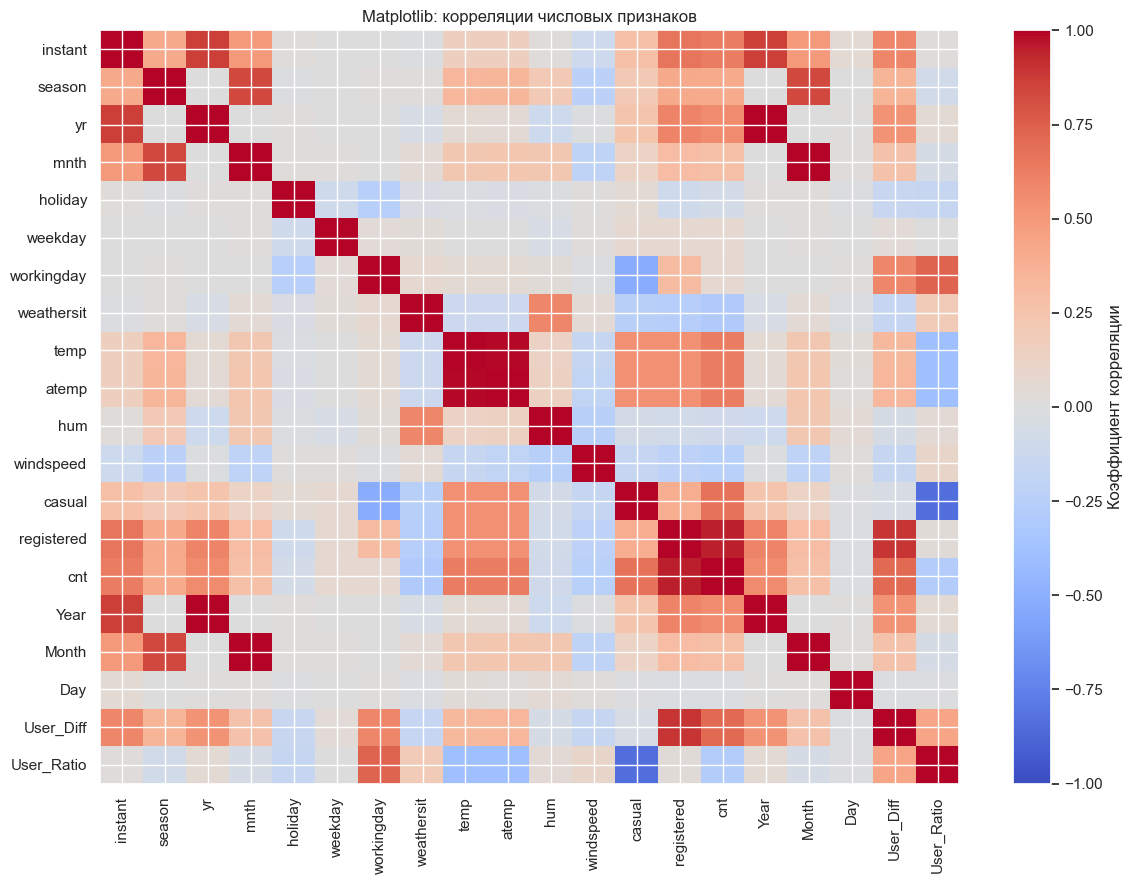

In [497]:
correlation = df.select_dtypes(include="number").corr()

plt.figure(figsize=(12, 9))

image = plt.imshow(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

plt.colorbar(image, label="Коэффициент корреляции")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(range(len(correlation.columns)), correlation.columns)

plt.title("Matplotlib: корреляции числовых признаков")
plt.tight_layout()
plt.show()


Seaborn:

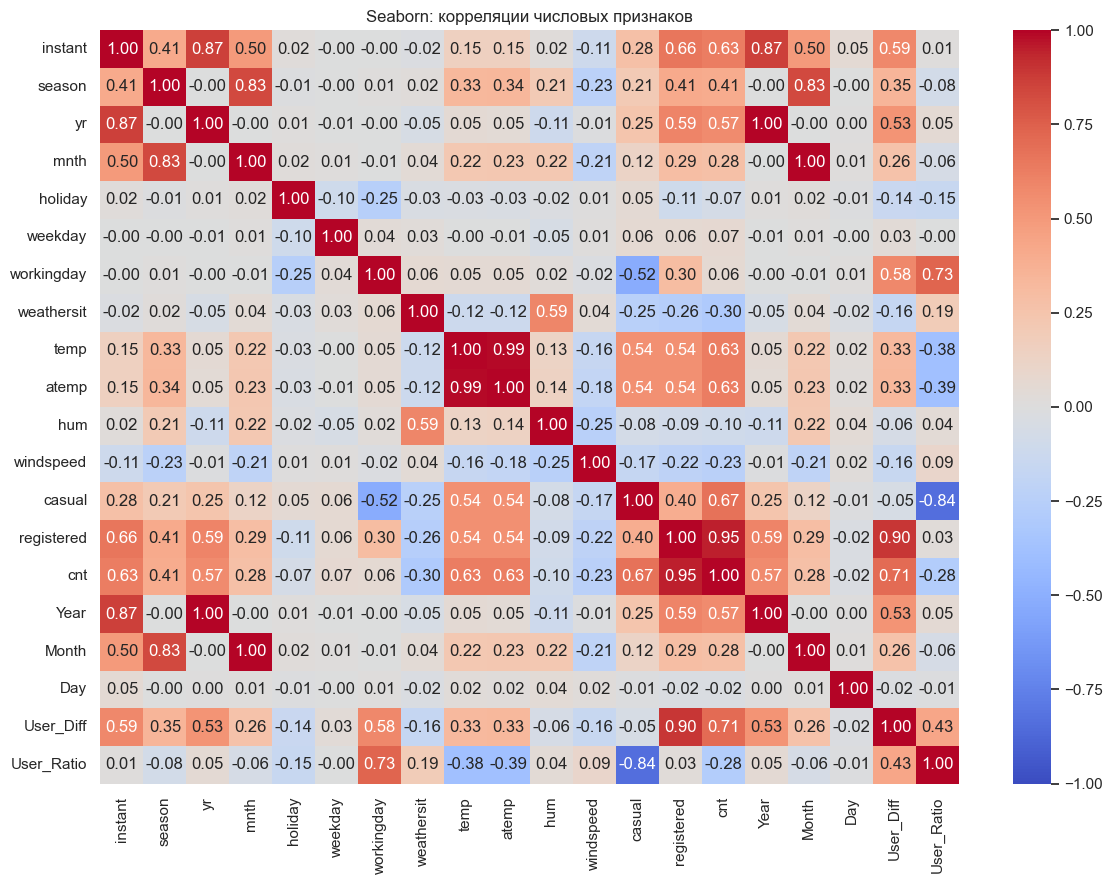

In [498]:
plt.figure(figsize=(12, 9))

sns.heatmap(
    correlation,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=True,
    fmt=".2f"
)

plt.title("Seaborn: корреляции числовых признаков")
plt.tight_layout()
plt.show()

#### Л. Регрессия: температура и дневной спрос

Matplotlib:

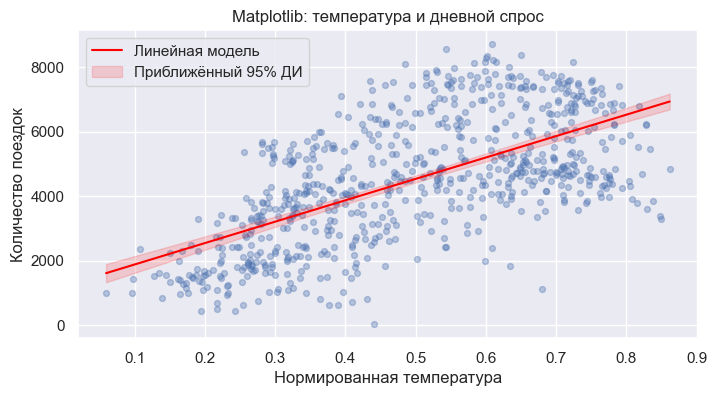

In [499]:
x = df["temp"].to_numpy()
y = df["cnt"].to_numpy()

coefficients = np.polyfit(x, y, 1)
model = np.poly1d(coefficients)

x_grid = np.linspace(x.min(), x.max(), 150)
predicted = model(x)
residual_std = np.sqrt(np.sum((y - predicted) ** 2) / (len(y) - 2))
sxx = np.sum((x - x.mean()) ** 2)

se_mean = residual_std * np.sqrt(
    1 / len(x) + (x_grid - x.mean()) ** 2 / sxx
)

plt.figure(figsize=(8, 4))
plt.scatter(x, y, alpha=0.35, s=18)
plt.plot(x_grid, model(x_grid), color="red", label="Линейная модель")

plt.fill_between(
    x_grid,
    model(x_grid) - 1.96 * se_mean,
    model(x_grid) + 1.96 * se_mean,
    color="red",
    alpha=0.15,
    label="Приближённый 95% ДИ"
)

plt.title("Matplotlib: температура и дневной спрос")
plt.xlabel("Нормированная температура")
plt.ylabel("Количество поездок")
plt.legend()
plt.show()

Seaborn:

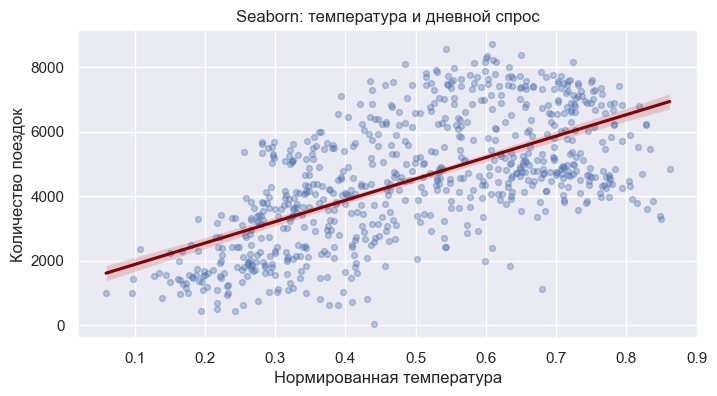

In [500]:
plt.figure(figsize=(8, 4))

sns.regplot(
    data=df,
    x="temp",
    y="cnt",
    scatter_kws={"alpha": 0.35, "s": 18},
    line_kws={"color": "darkred"}
)

plt.title("Seaborn: температура и дневной спрос")
plt.xlabel("Нормированная температура")
plt.ylabel("Количество поездок")
plt.show()

### 3.3. Таблица сравнения

| Тип графика | Matplotlib | Seaborn | Ручная агрегация | Настройка цветов и легенды вручную | Статистика из коробки | Удобство Matplotlib / Seaborn |
|---|---:|---:|---|---|---|---|
| А. Line | 9 | 9 | Нет | В Matplotlib | hue в Seaborn | 4 / 4 |
| Б. Hist | 8 | 6 | Нет | В Matplotlib | Группировка через hue | 3 / 5 |
| В. KDE | 11 | 6 | Вычисление KDE вручную | В Matplotlib | KDE в Seaborn | 2 / 5 |
| Г. Box | 8 | 6 | Подготовка списков | В Matplotlib | Квантили и выбросы | 3 / 5 |
| Д. Violin | 7 | 6 | Подготовка списков | В Matplotlib | Оценка плотности | 3 / 5 |
| Е. Bar | 7 | 6 | Среднее по сезонам | Небольшая | Агрегация и интервалы | 3 / 5 |
| Ж. Scatter | 7 | 6 | Нет | В Matplotlib | hue и size | 4 / 5 |
| З. Hist+KDE | 10 | 6 | Вычисление KDE вручную | В Matplotlib | kde=True | 3 / 5 |
| И. Pairplot | 14 | 2 | Нет | В Matplotlib | Автоматическая матрица | 2 / 5 |
| К. Heatmap | 9 | 5 | Матрица .corr() | В Matplotlib | Подписи через annot | 3 / 5 |
| Л. Regplot | 18 | 6 | Модель и интервал вручную | В Matplotlib | Регрессия и ДИ | 2 / 5 |

### 3.4 Сводная аналитика

1. Среднее количество строк кода

- Matplotlib:  9,82 строки
- Seaborn: 5,82 строки

В среднем Seaborn требует примерно на 41% меньше функциональных строк кода

2. Наибольшая разница в объёме кода

Наиболее заметная разница наблюдается у графиков Regplot и Pairplot: seaborn предоставляет готовые функции регрессии и построения матрицы зависимостей, тогда как в Matplotlib требуется больше ручных операций

3. Дополнительные возможности Seaborn

Seaborn упрощает построение KDE, регрессии с доверительным интервалом, автоматическую агрегацию в barplot(), группировку данных через hue и создание матрицы зависимостей через pairplot(). Эти возможности реализуемы и с Matplotlib, но требуют больше кода или дополнительных библиотек

4. Пример преимущества Matplotlib

Matplotlib даёт больше контроля над оформлением и вычислениями. Например, при построении регрессии можно самостоятельно рассчитать модель и доверительный интервал, а затем полностью настроить их отображение


### Часть 4. Аналитическая записка

1. Удобство

Seaborn оказался удобнее для статистических графиков. Например, pairplot() автоматически создаёт матрицу зависимостей, kdeplot() строит оценку плотности, а regplot() отображает регрессию с доверительным интервалом

2. Функциональность

Наиболее полезны автоматическая агрегация, палитры, легенды и параметры hue и size. Они упрощают сравнение групп и отображение нескольких признаков. Однако для нестандартных вычислений и оформления готовых функций может быть недостаточно

3. Контроль

Matplotlib позволяет отдельно настраивать каждый элемент графика. Например, при построении регрессии вручную пришлось вычислять коэффициенты модели и доверительный интервал. В Seaborn это выполняется автоматически, но с меньшим прямым контролем над расчётами

4. Воспроизводимость

Для десятков однотипных графиков удобнее Seaborn в сочетании с общими функциями настройки. Это позволяет сохранять единый стиль и сокращать повторяющийся код

5. Ограничения

Matplotlib предпочтительнее для нестандартных графиков, сложных композиций и собственных алгоритмов расчёта. Он предоставляет более низкоуровневый контроль над визуализацией

6. Итоговый выбор

Для повседневного анализа я бы выбрал Seaborn: он сокращает код и упрощает статистическую визуализацию. Matplotlib лучше подходит для тонкой настройки и специализированных задач

7. Стратегия

Seaborn стоит использовать для типовых статистических графиков, а Matplotlib — для нестандартных визуализаций и детальной настройки. Оптимален смешанный подход: строить график в Seaborn, а затем при необходимости дорабатывать его средствами Matplotlib